In [2]:
def recursive_fibonacci(n):
    if n <= 1:
        return n
    return recursive_fibonacci(n - 1) + recursive_fibonacci(n - 2)


def iterative_fibonacci(n):
    a, b = 0, 1
    for i in range(n):
        a, b = b, a + b
    return a


n = 10
print("Recursive Fibonacci:", recursive_fibonacci(n))
print("Iterative Fibonacci:", iterative_fibonacci(n))

print("\nTime and Space Complexity")
print("Iterative : Time O(n), Space O(1)")
print("Recursive : Time O(2^n), Space O(n)")

Recursive Fibonacci: 55
Iterative Fibonacci: 55

Time and Space Complexity
Iterative : Time O(n), Space O(1)
Recursive : Time O(2^n), Space O(n)


# Analysis: Time and Memory Comparison (n = 1 to 30)

N	Recursive Time (s)	Iterative Time (s)
1	0.00000020		0.00000020
2	0.00000020		0.00000010
3	0.00000020		0.00000020
4	0.00000040		0.00000020
5	0.00000060		0.00000020
6	0.00000090		0.00000020
7	0.00000140		0.00000020
8	0.00000220		0.00000030
9	0.00000370		0.00000030
10	0.00000590		0.00000030
11	0.00000960		0.00000030
12	0.00001530		0.00000030
13	0.00002460		0.00000040
14	0.00003850		0.00000030
15	0.00006030		0.00000030
16	0.00010320		0.00000050
17	0.00016520		0.00000040
18	0.00025720		0.00000050
19	0.00060700		0.00000040
20	0.00070690		0.00000050
21	0.00112970		0.00000130
22	0.00212620		0.00000060
23	0.00297110		0.00000060
24	0.00483400		0.00000060
25	0.00812320		0.00000060
26	0.01363810		0.00000060
27	0.02164180		0.00000070
28	0.03571130		0.00000070
29	0.06362660		0.00000160
30	0.10112090		0.00000080

N	Recursive Memory (KB)	Iterative Memory (KB)
1	0.0000			0.0781
2	0.0000			0.0781
3	0.0000			0.0781
4	0.0000			0.0781
5	0.0000			0.0781
6	0.0000			0.0781
7	0.0000			0.0781
8	0.0000			0.078

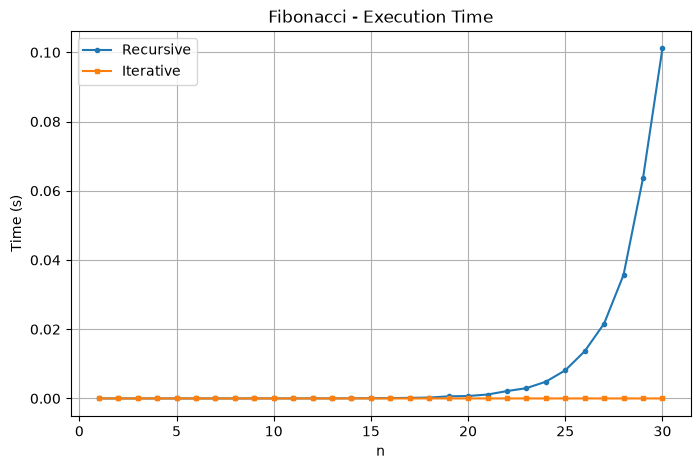

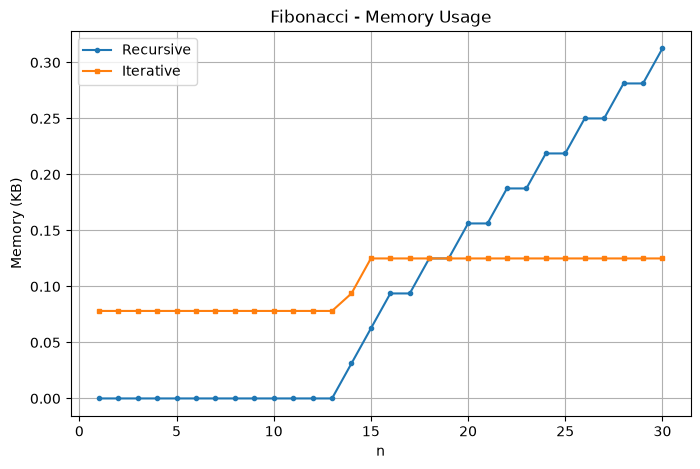

In [3]:
import matplotlib.pyplot as plt
from time import perf_counter
import tracemalloc
import statistics


def measure_time(function, n, repeats=5):
    times = []
    for _ in range(repeats):
        start = perf_counter()
        function(n)
        times.append(perf_counter() - start)
    return statistics.median(times)


def measure_memory(function, n, repeats=3):
    memory_values = []
    for _ in range(repeats):
        tracemalloc.start()
        function(n)
        _, peak = tracemalloc.get_traced_memory()
        tracemalloc.stop()
        memory_values.append(peak / 1024)
    return statistics.median(memory_values)


x = list(range(1, 31))
recursive_times = []
iterative_times = []
recursive_memory = []
iterative_memory = []

for n in x:
    recursive_times.append(measure_time(recursive_fibonacci, n))
    iterative_times.append(measure_time(iterative_fibonacci, n))
    recursive_memory.append(measure_memory(recursive_fibonacci, n))
    iterative_memory.append(measure_memory(iterative_fibonacci, n))


print("N\tRecursive Time (s)\tIterative Time (s)")
for n, rt, it in zip(x, recursive_times, iterative_times):
    print(f"{n}\t{rt:.8f}\t\t{it:.8f}")

print("\nN\tRecursive Memory (KB)\tIterative Memory (KB)")
for n, rm, im in zip(x, recursive_memory, iterative_memory):
    print(f"{n}\t{rm:.4f}\t\t\t{im:.4f}")


plt.figure(figsize=(8, 5))
plt.plot(x, recursive_times, marker='o', markersize=3, label="Recursive")
plt.plot(x, iterative_times, marker='s', markersize=3, label="Iterative")
plt.xlabel("n")
plt.ylabel("Time (s)")
plt.title("Fibonacci - Execution Time")
plt.legend()
plt.grid(True)
plt.show()


plt.figure(figsize=(8, 5))
plt.plot(x, recursive_memory, marker='o', markersize=3, label="Recursive")
plt.plot(x, iterative_memory, marker='s', markersize=3, label="Iterative")
plt.xlabel("n")
plt.ylabel("Memory (KB)")
plt.title("Fibonacci - Memory Usage")
plt.legend()
plt.grid(True)
plt.show()